<a href="https://colab.research.google.com/github/ishankanani/Credit-Card-fraud-Detection/blob/main/Ikanani.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## 1 - Environment



In [1]:
import sys
import platform
import random
import statistics
import time
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms
from IPython.display import Markdown, display

print("Python executable:", sys.executable)
print("Python:", platform.python_version())
print("PyTorch:", torch.__version__)
print("TorchVision:", torchvision.__version__)

Python executable: /usr/bin/python3
Python: 3.13.16
PyTorch: 2.11.0+cpu
TorchVision: 0.26.0+cpu


###  - Computing device


In [2]:
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Selected device:", DEVICE)
if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
    print("CUDA runtime reported by PyTorch:", torch.version.cuda)
else:
    print("CUDA is unavailable in this kernel; the notebook will run on CPU.")

Selected device: cpu
CUDA is unavailable in this kernel; the notebook will run on CPU.


###  - Reproducibility


In [3]:
SEED = 42
NUM_CLASSES = 10
IMAGE_SIZE = 28
DATA_ROOT = Path("data")

def seed_everything(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False

seed_everything()
print("Random seed:", SEED)

Random seed: 42


## 2 - MNIST dataset
MNIST contains 28 × 28 grayscale images of digits 0–9. The 784 pixel values form the input, and the largest output activation determines the predicted digit. Training adjusts weights and biases using labeled examples.

`ToTensor()` scales the pixels to [0, 1]. The custom model also standardizes its input inside the forward pass.

###  - Import MNIST


In [4]:
transform = transforms.ToTensor()

train_full = datasets.MNIST(
    root=DATA_ROOT,
    train=True,
    download=True,
    transform=transform,
)
test_dataset = datasets.MNIST(
    root=DATA_ROOT,
    train=False,
    download=True,
    transform=transform,
)

train_targets = train_full.targets.to(torch.long)
test_targets = test_dataset.targets.to(torch.long)
print(f"Official training examples: {len(train_full):,}")
print(f"Official test examples:     {len(test_dataset):,}")
print("Image tensor shape:", tuple(train_full[0][0].shape))
print("Pixel range:", float(train_full[0][0].min()), "to", float(train_full[0][0].max()))

100%|██████████| 9.91M/9.91M [00:00<00:00, 12.9MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 341kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 3.22MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 10.0MB/s]


Official training examples: 60,000
Official test examples:     10,000
Image tensor shape: (1, 28, 28)
Pixel range: 0.0 to 1.0


###  - Display sample images


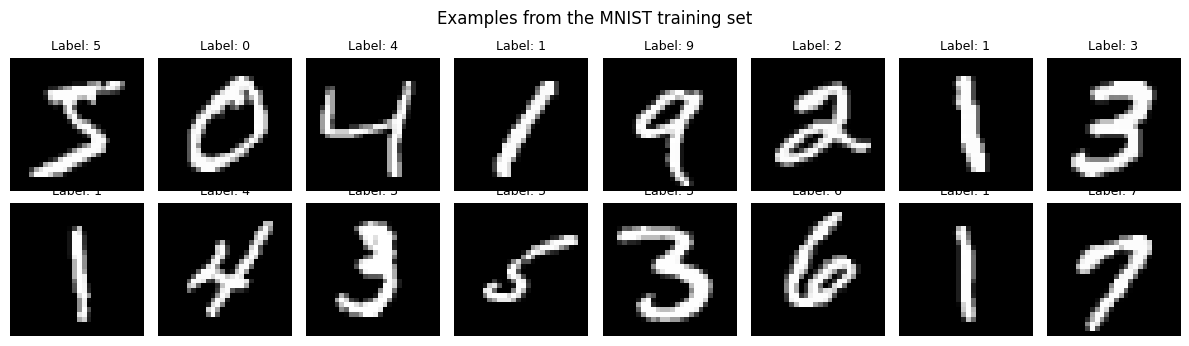

In [5]:
fig, axes = plt.subplots(2, 8, figsize=(12, 3.5))
for index, ax in enumerate(axes.flat):
    image, label = train_full[index]
    ax.imshow(image.squeeze(0), cmap="gray")
    ax.set_title(f"Label: {label}", fontsize=9)
    ax.axis("off")
fig.suptitle("Examples from the MNIST training set")
plt.tight_layout()
plt.show()

## 3 - Training, validation and test sets
The 60,000 training images are split by digit class into 54,000 training and 6,000 validation images. The official 10,000-image test set stays separate.


 - Stratified data split


In [6]:
def validation_counts_by_class(class_sizes, validation_fraction):
    # Allocate whole examples while keeping the requested total exact.
    quotas = [size * validation_fraction for size in class_sizes]
    counts = [int(quota) for quota in quotas]
    remaining = round(sum(class_sizes) * validation_fraction) - sum(counts)
    priority = sorted(
        range(len(class_sizes)),
        key=lambda digit: quotas[digit] - counts[digit],
        reverse=True,
    )
    for digit in priority[:remaining]:
        counts[digit] += 1
    return counts


def stratified_train_validation_split(targets, validation_fraction=0.10, seed=SEED):
    """Return disjoint, class-stratified index tensors."""
    generator = torch.Generator().manual_seed(seed)
    train_parts, validation_parts = [], []
    class_sizes = torch.bincount(targets, minlength=NUM_CLASSES).tolist()
    validation_counts = validation_counts_by_class(class_sizes, validation_fraction)
    for digit in range(NUM_CLASSES):
        class_indices = torch.where(targets == digit)[0]
        class_indices = class_indices[torch.randperm(len(class_indices), generator=generator)]
        n_validation = validation_counts[digit]
        validation_parts.append(class_indices[:n_validation])
        train_parts.append(class_indices[n_validation:])

    train_indices = torch.cat(train_parts)
    validation_indices = torch.cat(validation_parts)
    train_indices = train_indices[torch.randperm(len(train_indices), generator=generator)]
    validation_indices = validation_indices[torch.randperm(len(validation_indices), generator=generator)]
    return train_indices, validation_indices


train_indices, validation_indices = stratified_train_validation_split(train_targets)
train_dataset = Subset(train_full, train_indices.tolist())
validation_dataset = Subset(train_full, validation_indices.tolist())

assert len(train_dataset) == 54_000
assert len(validation_dataset) == 6_000
assert set(train_indices.tolist()).isdisjoint(validation_indices.tolist())
print(f"Training split:   {len(train_dataset):,}")
print(f"Validation split: {len(validation_dataset):,}")
print("The official test set remains untouched until final evaluation.")

Training split:   54,000
Validation split: 6,000
The official test set remains untouched until final evaluation.


- Check the class distribution


In [7]:
def class_counts(targets, indices):
    return torch.bincount(targets[indices], minlength=NUM_CLASSES)

split_counts = torch.stack([
    class_counts(train_targets, train_indices),
    class_counts(train_targets, validation_indices),
])
original_counts = torch.bincount(train_targets, minlength=NUM_CLASSES)
print("Rows: training, validation. Columns: digit 0 through 9.")
print(split_counts)
# MNIST classes have different sizes. Check conservation and proportions.
assert torch.equal(split_counts.sum(dim=0), original_counts)
assert int(split_counts[0].sum()) == 54_000
assert int(split_counts[1].sum()) == 6_000
assert torch.all((split_counts[1] - original_counts * 0.10).abs() <= 1)
print("Split checks passed: exact totals, preserved labels and stratification.")

Rows: training, validation. Columns: digit 0 through 9.
tensor([[5331, 6068, 5362, 5518, 5258, 4879, 5326, 5638, 5266, 5354],
        [ 592,  674,  596,  613,  584,  542,  592,  627,  585,  595]])
Split checks passed: exact totals, preserved labels and stratification.


## 4 - Network architectures
- Vanilla network

The vanilla network follows the **784 → 16 → 16 → 10**.
 - Custom network

The custom network uses **784 → 256 → 128 → 10**,



In [8]:
MODEL_CONFIGS = {
    "Vanilla 3B1B-style": {
        "hidden_sizes": (16, 16),
        "activation": "sigmoid",
        "output_sigmoid": True,
        "dropout": 0.0,
        "normalize": False,
        "loss": "mse",
        "optimizer": "sgd",
        "learning_rate": 0.5,
        "weight_decay": 0.0,
        "batch_size": 100,
    },
    "Custom MLP": {
        "hidden_sizes": (256, 128),
        "activation": "relu",
        "output_sigmoid": False,
        "dropout": 0.20,
        "normalize": True,
        "loss": "cross_entropy",
        "optimizer": "adamw",
        "learning_rate": 1e-3,
        "weight_decay": 1e-4,
        "batch_size": 128,
    },
}


class MNISTMLP(nn.Module):
    def __init__(self, hidden_sizes, activation, output_sigmoid, dropout, normalize):
        super().__init__()
        hidden_1, hidden_2 = hidden_sizes
        self.fc1 = nn.Linear(IMAGE_SIZE * IMAGE_SIZE, hidden_1)
        self.fc2 = nn.Linear(hidden_1, hidden_2)
        self.fc3 = nn.Linear(hidden_2, NUM_CLASSES)
        self.activation_name = activation
        self.activation = nn.Sigmoid() if activation == "sigmoid" else nn.ReLU()
        self.dropout1 = nn.Dropout(dropout)
        self.dropout2 = nn.Dropout(dropout)
        self.output_sigmoid = output_sigmoid
        self.normalize = normalize

        linear_layers = [self.fc1, self.fc2, self.fc3]
        for layer in linear_layers:
            if activation == "relu" and layer is not self.fc3:
                nn.init.kaiming_uniform_(layer.weight, nonlinearity="relu")
            else:
                nn.init.xavier_uniform_(layer.weight)
            nn.init.zeros_(layer.bias)

    def forward(self, images):
        # Flatten each 1 × 28 × 28 image into 784 input features.
        values = images.flatten(start_dim=1)
        if self.normalize:
            values = (values - 0.1307) / 0.3081
        values = self.dropout1(self.activation(self.fc1(values)))
        values = self.dropout2(self.activation(self.fc2(values)))
        outputs = self.fc3(values)
        if self.output_sigmoid:
            outputs = torch.sigmoid(outputs)
        return outputs


def build_model(config):
    return MNISTMLP(
        hidden_sizes=config["hidden_sizes"],
        activation=config["activation"],
        output_sigmoid=config["output_sigmoid"],
        dropout=config["dropout"],
        normalize=config["normalize"],
    )


def count_parameters(model):
    return sum(parameter.numel() for parameter in model.parameters() if parameter.requires_grad)

for name, config in MODEL_CONFIGS.items():
    preview_model = build_model(config)
    print(f"{name}: {count_parameters(preview_model):,} trainable parameters")
    del preview_model

Vanilla 3B1B-style: 13,002 trainable parameters
Custom MLP: 235,146 trainable parameters


 - Loss and training functions
The vanilla cost is the mean, over a batch, of the sum of squared output errors:


Labels are one-hot encoded for this loss. The custom model uses cross-entropy with integer labels. The two losses have different scales, so model performance is compared using accuracy and F1.

PyTorch calculates gradients with `loss.backward()`. Batches and models use the selected device; pinned memory and non-blocking transfers are enabled for CUDA. `num_workers=0` supports Windows notebook kernels.

In [9]:
def make_loader(dataset, batch_size, shuffle=False, seed=SEED):
    generator = torch.Generator().manual_seed(seed)
    return DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=shuffle,
        num_workers=0,
        pin_memory=(DEVICE.type == "cuda"),
        generator=generator,
    )


def compute_loss(outputs, labels, loss_name):
    if loss_name == "mse":
        one_hot = F.one_hot(labels, num_classes=NUM_CLASSES).to(dtype=outputs.dtype)
        per_image_squared_error = (outputs - one_hot).square().sum(dim=1)
        return per_image_squared_error.mean()
    return F.cross_entropy(outputs, labels)


def make_optimizer(model, config):
    if config["optimizer"] == "sgd":
        return torch.optim.SGD(model.parameters(), lr=config["learning_rate"])
    return torch.optim.AdamW(
        model.parameters(),
        lr=config["learning_rate"],
        weight_decay=config["weight_decay"],
    )


def train_one_epoch(model, loader, optimizer, config):
    model.train()
    total_loss = torch.zeros((), device=DEVICE)
    total_examples = 0
    for images, labels in loader:
        images = images.to(DEVICE, non_blocking=(DEVICE.type == "cuda"))
        labels = labels.to(DEVICE, non_blocking=(DEVICE.type == "cuda"))

        optimizer.zero_grad(set_to_none=True)
        outputs = model(images)
        loss = compute_loss(outputs, labels, config["loss"])
        loss.backward()
        optimizer.step()

        batch_size = labels.size(0)
        total_loss += loss.detach() * batch_size
        total_examples += batch_size
    return (total_loss / total_examples).item()

 Evaluation functions


In [10]:
@torch.inference_mode()
def evaluate(model, loader, config):
    model.eval()
    total_loss = torch.zeros((), device=DEVICE)
    total_examples = 0
    confusion = torch.zeros((NUM_CLASSES, NUM_CLASSES), dtype=torch.long, device=DEVICE)

    for images, labels in loader:
        images = images.to(DEVICE, non_blocking=(DEVICE.type == "cuda"))
        labels_device = labels.to(DEVICE, non_blocking=(DEVICE.type == "cuda"))
        outputs = model(images)
        loss = compute_loss(outputs, labels_device, config["loss"])
        predictions = outputs.argmax(dim=1)

        batch_size = labels_device.size(0)
        total_loss += loss.detach() * batch_size
        total_examples += batch_size
        flat_counts = torch.bincount(
            labels_device * NUM_CLASSES + predictions,
            minlength=NUM_CLASSES * NUM_CLASSES,
        )
        confusion += flat_counts.reshape(NUM_CLASSES, NUM_CLASSES)

    confusion_cpu = confusion.to("cpu")
    mean_loss = (total_loss / total_examples).item()
    return mean_loss, metrics_from_confusion(confusion_cpu), confusion_cpu


def metrics_from_confusion(confusion):
    counts = confusion.to(torch.float64)
    true_positives = counts.diag()
    support = counts.sum(dim=1)
    predicted_count = counts.sum(dim=0)
    precision = true_positives / predicted_count.clamp_min(1)
    recall = true_positives / support.clamp_min(1)
    f1 = 2 * precision * recall / (precision + recall).clamp_min(1e-12)
    accuracy = true_positives.sum() / counts.sum().clamp_min(1)
    return {
        "accuracy": float(accuracy),
        "macro_precision": float(precision.mean()),
        "macro_recall": float(recall.mean()),
        "macro_f1": float(f1.mean()),
        "per_class_precision": precision,
        "per_class_recall": recall,
        "per_class_f1": f1,
        "support": support,
    }

## 5 - Stratified 3-fold cross-validation
Both configurations use the same three folds from all 54,000 training images. For each fold, a fresh model trains on two folds for five epochs and is evaluated on the remaining fold. Every training image is used for fold validation once.

Mean accuracy and standard deviation summarize this fixed-budget comparison. The final models are trained separately for longer.

- Create the folds


In [11]:
CV_SPLITS = 3
CV_EPOCHS = 5

def stratified_kfold(indices, targets, n_splits=CV_SPLITS, seed=SEED):
    generator = torch.Generator().manual_seed(seed)
    validation_parts_by_fold = [[] for _ in range(n_splits)]
    for digit in range(NUM_CLASSES):
        class_indices = indices[targets[indices] == digit]
        class_indices = class_indices[torch.randperm(len(class_indices), generator=generator)]
        for fold_number, part in enumerate(torch.tensor_split(class_indices, n_splits)):
            validation_parts_by_fold[fold_number].append(part)

    folds = []
    for fold_number in range(n_splits):
        validation_fold = torch.cat(validation_parts_by_fold[fold_number])
        training_fold = torch.cat([
            part
            for other_fold, fold_parts in enumerate(validation_parts_by_fold)
            if other_fold != fold_number
            for part in fold_parts
        ])
        training_fold = training_fold[torch.randperm(len(training_fold), generator=generator)]
        validation_fold = validation_fold[torch.randperm(len(validation_fold), generator=generator)]
        folds.append((training_fold, validation_fold))
    return folds


cv_indices = train_indices
cv_folds = stratified_kfold(cv_indices, train_targets)
seen_validation_indices = []
for training_fold, validation_fold in cv_folds:
    assert set(training_fold.tolist()).isdisjoint(validation_fold.tolist())
    assert len(training_fold) + len(validation_fold) == len(cv_indices)
    seen_validation_indices.extend(validation_fold.tolist())
assert sorted(seen_validation_indices) == sorted(cv_indices.tolist())
assert set(cv_indices.tolist()).isdisjoint(validation_indices.tolist())
print(f"Cross-validation examples: {len(cv_indices):,}")
print(f"First fold training/validation sizes: {len(cv_folds[0][0]):,} / {len(cv_folds[0][1]):,}")

Cross-validation examples: 54,000
First fold training/validation sizes: 35,995 / 18,005


 - Train and evaluate each fold


In [12]:

cv_results = {}

def run_cross_validation():
    summaries = {}
    for model_number, (model_name, config) in enumerate(MODEL_CONFIGS.items()):
        fold_accuracies = []
        fold_times = []
        for fold_number, (fold_train_indices, fold_validation_indices) in enumerate(cv_folds, start=1):
            seed_everything(SEED + model_number * 100 + fold_number)
            fold_train_dataset = Subset(train_full, fold_train_indices.tolist())
            fold_validation_dataset = Subset(train_full, fold_validation_indices.tolist())
            train_loader = make_loader(
                fold_train_dataset, config["batch_size"], shuffle=True,
                seed=SEED + model_number * 100 + fold_number,
            )
            validation_loader = make_loader(
                fold_validation_dataset, config["batch_size"], shuffle=False,
            )

            model = build_model(config).to(DEVICE)
            optimizer = make_optimizer(model, config)
            if DEVICE.type == "cuda":
                torch.cuda.synchronize()
            start = time.perf_counter()
            for epoch in range(1, CV_EPOCHS + 1):
                fold_loss = train_one_epoch(model, train_loader, optimizer, config)
                print(f"{model_name}, fold {fold_number}, epoch {epoch}/{CV_EPOCHS}: loss={fold_loss:.4f}", flush=True)
            if DEVICE.type == "cuda":
                torch.cuda.synchronize()
            fold_times.append(time.perf_counter() - start)

            _, fold_metrics, _ = evaluate(model, validation_loader, config)
            fold_accuracies.append(fold_metrics["accuracy"])
            print(f"{model_name}, fold {fold_number}: validation accuracy = {fold_metrics['accuracy']:.2%}")
            del model, optimizer, train_loader, validation_loader
            if DEVICE.type == "cuda":
                torch.cuda.empty_cache()

        summaries[model_name] = {
            "fold_accuracies": fold_accuracies,
            "mean_accuracy": statistics.mean(fold_accuracies),
            "std_accuracy": statistics.stdev(fold_accuracies),
            "wall_time_seconds": sum(fold_times),
        }
    return summaries

In [13]:
%%time
cv_results.clear()
cv_results.update(run_cross_validation())

Vanilla 3B1B-style, fold 1, epoch 1/5: loss=0.8809
Vanilla 3B1B-style, fold 1, epoch 2/5: loss=0.6524
Vanilla 3B1B-style, fold 1, epoch 3/5: loss=0.4225
Vanilla 3B1B-style, fold 1, epoch 4/5: loss=0.3139
Vanilla 3B1B-style, fold 1, epoch 5/5: loss=0.2508
Vanilla 3B1B-style, fold 1: validation accuracy = 87.49%
Vanilla 3B1B-style, fold 2, epoch 1/5: loss=0.8887
Vanilla 3B1B-style, fold 2, epoch 2/5: loss=0.6870
Vanilla 3B1B-style, fold 2, epoch 3/5: loss=0.4514
Vanilla 3B1B-style, fold 2, epoch 4/5: loss=0.3518
Vanilla 3B1B-style, fold 2, epoch 5/5: loss=0.2745
Vanilla 3B1B-style, fold 2: validation accuracy = 81.61%
Vanilla 3B1B-style, fold 3, epoch 1/5: loss=0.9033
Vanilla 3B1B-style, fold 3, epoch 2/5: loss=0.7235
Vanilla 3B1B-style, fold 3, epoch 3/5: loss=0.4841
Vanilla 3B1B-style, fold 3, epoch 4/5: loss=0.3408
Vanilla 3B1B-style, fold 3, epoch 5/5: loss=0.2613
Vanilla 3B1B-style, fold 3: validation accuracy = 86.10%
Custom MLP, fold 1, epoch 1/5: loss=0.4202
Custom MLP, fold 1, e

 - Cross-validation results


In [14]:
print("Stratified 3-fold cross-validation results")
for model_name, summary in cv_results.items():
    scores = ", ".join(f"{score:.2%}" for score in summary["fold_accuracies"])
    print(
        f"{model_name:20s} folds=[{scores}]  "
        f"mean={summary['mean_accuracy']:.2%} ± {summary['std_accuracy']:.2%}  "
        f"CV time={summary['wall_time_seconds']:.1f}s"
    )

Stratified 3-fold cross-validation results
Vanilla 3B1B-style   folds=[87.49%, 81.61%, 86.10%]  mean=85.06% ± 3.07%  CV time=69.8s
Custom MLP           folds=[96.77%, 96.91%, 97.04%]  mean=96.90% ± 0.14%  CV time=92.9s


## 6 - Final training
Each model trains on all 54,000 training images for up to 12 epochs. Training stops after three epochs without a sufficient validation-loss improvement, and the best checkpoint is restored.

`%%time` records each cell's wall time, including validation and checkpoint handling. The fit function separately records training-loop time, synchronizing CUDA before and after timing.

- Training procedure


In [15]:
final_fits = {}

MAX_EPOCHS = 12
EARLY_STOPPING_PATIENCE = 3
MIN_VALIDATION_LOSS_IMPROVEMENT = 1e-4

train_loader_by_model = {
    name: make_loader(
        train_dataset,
        config["batch_size"],
        shuffle=True,
        seed=SEED + 10,
    )
    for name, config in MODEL_CONFIGS.items()
}
validation_loader_by_model = {
    name: make_loader(validation_dataset, config["batch_size"], shuffle=False)
    for name, config in MODEL_CONFIGS.items()
}


def fit_final_model(model_name, config):
    seed_everything(SEED + 500)
    model = build_model(config).to(DEVICE)
    optimizer = make_optimizer(model, config)
    train_loader = train_loader_by_model[model_name]
    validation_loader = validation_loader_by_model[model_name]

    if DEVICE.type == "cuda":
        torch.cuda.reset_peak_memory_stats()
    history = []
    best_validation_loss = float("inf")
    best_state = None
    best_epoch = 0
    epochs_without_improvement = 0
    training_seconds = 0.0

    for epoch in range(1, MAX_EPOCHS + 1):
        if DEVICE.type == "cuda":
            torch.cuda.synchronize()
        epoch_start = time.perf_counter()
        train_loss = train_one_epoch(model, train_loader, optimizer, config)
        if DEVICE.type == "cuda":
            torch.cuda.synchronize()
        training_seconds += time.perf_counter() - epoch_start

        validation_loss, validation_metrics, _ = evaluate(model, validation_loader, config)
        history.append({
            "epoch": epoch,
            "train_loss": train_loss,
            "validation_loss": validation_loss,
            "validation_accuracy": validation_metrics["accuracy"],
        })
        print(
            f"{model_name} | epoch {epoch:02d} | "
            f"train loss {train_loss:.4f} | validation loss {validation_loss:.4f} | "
            f"validation accuracy {validation_metrics['accuracy']:.2%}"
        )

        if validation_loss < best_validation_loss - MIN_VALIDATION_LOSS_IMPROVEMENT:
            best_validation_loss = validation_loss
            best_epoch = epoch
            best_state = {
                key: value.detach().cpu().clone()
                for key, value in model.state_dict().items()
            }
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1
            if epochs_without_improvement >= EARLY_STOPPING_PATIENCE:
                print(f"Early stopping after epoch {epoch}; best epoch was {best_epoch}.")
                break

    if best_state is None:
        raise RuntimeError("No validation checkpoint was recorded.")
    model.load_state_dict(best_state)
    peak_memory_mb = (
        torch.cuda.max_memory_allocated() / (1024 ** 2)
        if DEVICE.type == "cuda" else None
    )
    return model, history, best_epoch, training_seconds, peak_memory_mb

 - Train the vanilla model


In [16]:
%%time
final_fits.update({
    "Vanilla 3B1B-style": fit_final_model("Vanilla 3B1B-style", MODEL_CONFIGS["Vanilla 3B1B-style"])
})

Vanilla 3B1B-style | epoch 01 | train loss 0.8498 | validation loss 0.6947 | validation accuracy 49.17%
Vanilla 3B1B-style | epoch 02 | train loss 0.5347 | validation loss 0.3936 | validation accuracy 81.55%
Vanilla 3B1B-style | epoch 03 | train loss 0.3106 | validation loss 0.2450 | validation accuracy 87.55%
Vanilla 3B1B-style | epoch 04 | train loss 0.2161 | validation loss 0.1916 | validation accuracy 89.38%
Vanilla 3B1B-style | epoch 05 | train loss 0.1795 | validation loss 0.1684 | validation accuracy 89.90%
Vanilla 3B1B-style | epoch 06 | train loss 0.1603 | validation loss 0.1529 | validation accuracy 90.42%
Vanilla 3B1B-style | epoch 07 | train loss 0.1477 | validation loss 0.1439 | validation accuracy 91.03%
Vanilla 3B1B-style | epoch 08 | train loss 0.1386 | validation loss 0.1368 | validation accuracy 91.28%
Vanilla 3B1B-style | epoch 09 | train loss 0.1315 | validation loss 0.1306 | validation accuracy 91.73%
Vanilla 3B1B-style | epoch 10 | train loss 0.1258 | validation l

- Train the custom model


In [17]:
%%time
final_fits.update({
    "Custom MLP": fit_final_model("Custom MLP", MODEL_CONFIGS["Custom MLP"])
})

Custom MLP | epoch 01 | train loss 0.3665 | validation loss 0.1532 | validation accuracy 95.28%
Custom MLP | epoch 02 | train loss 0.1604 | validation loss 0.0990 | validation accuracy 96.93%
Custom MLP | epoch 03 | train loss 0.1188 | validation loss 0.0837 | validation accuracy 97.47%
Custom MLP | epoch 04 | train loss 0.0996 | validation loss 0.0753 | validation accuracy 97.80%
Custom MLP | epoch 05 | train loss 0.0844 | validation loss 0.0759 | validation accuracy 97.80%
Custom MLP | epoch 06 | train loss 0.0741 | validation loss 0.0729 | validation accuracy 97.93%
Custom MLP | epoch 07 | train loss 0.0648 | validation loss 0.0730 | validation accuracy 97.75%
Custom MLP | epoch 08 | train loss 0.0603 | validation loss 0.0661 | validation accuracy 98.27%
Custom MLP | epoch 09 | train loss 0.0560 | validation loss 0.0682 | validation accuracy 97.98%
Custom MLP | epoch 10 | train loss 0.0500 | validation loss 0.0751 | validation accuracy 98.07%
Custom MLP | epoch 11 | train loss 0.043

## 7 - Test evaluation
Accuracy, macro precision, macro recall and macro F1 are calculated from the test confusion matrix. Macro averages give each digit equal weight. Training and validation accuracy are also reported to check generalization.

In [18]:
# Unpack in a normal Python cell so VS Code can resolve these names.
vanilla_model, vanilla_history, vanilla_best_epoch, vanilla_train_seconds, vanilla_peak_memory_mb = final_fits["Vanilla 3B1B-style"]
custom_model, custom_history, custom_best_epoch, custom_train_seconds, custom_peak_memory_mb = final_fits["Custom MLP"]

test_loader = make_loader(test_dataset, batch_size=256, shuffle=False)
train_evaluation_loader = {
    name: make_loader(train_dataset, config["batch_size"], shuffle=False)
    for name, config in MODEL_CONFIGS.items()
}
models = {
    "Vanilla 3B1B-style": vanilla_model,
    "Custom MLP": custom_model,
}
histories = {
    "Vanilla 3B1B-style": vanilla_history,
    "Custom MLP": custom_history,
}
training_seconds = {
    "Vanilla 3B1B-style": vanilla_train_seconds,
    "Custom MLP": custom_train_seconds,
}
peak_memory_mb = {
    "Vanilla 3B1B-style": vanilla_peak_memory_mb,
    "Custom MLP": custom_peak_memory_mb,
}
best_epochs = {
    "Vanilla 3B1B-style": vanilla_best_epoch,
    "Custom MLP": custom_best_epoch,
}

final_results = {}
confusion_matrices = {}
for model_name, model in models.items():
    config = MODEL_CONFIGS[model_name]
    train_loss, train_metrics, _ = evaluate(model, train_evaluation_loader[model_name], config)
    validation_loss, validation_metrics, _ = evaluate(model, validation_loader_by_model[model_name], config)
    test_loss, test_metrics, confusion = evaluate(model, test_loader, config)
    final_results[model_name] = {
        "train_loss": train_loss,
        "train": train_metrics,
        "validation_loss": validation_loss,
        "validation": validation_metrics,
        "test_loss": test_loss,
        "test": test_metrics,
        "parameters": count_parameters(model),
        "training_seconds": training_seconds[model_name],
        "best_epoch": best_epochs[model_name],
        "epochs_run": len(histories[model_name]),
        "peak_memory_mb": peak_memory_mb[model_name],
    }
    confusion_matrices[model_name] = confusion


table = [
    "| Metric | Vanilla | Custom |",
    "|---|---:|---:|",
]
vanilla_result = final_results["Vanilla 3B1B-style"]
custom_result = final_results["Custom MLP"]
for label, metric in [
    ("Test accuracy", "accuracy"), ("Macro precision", "macro_precision"),
    ("Macro recall", "macro_recall"), ("Macro F1", "macro_f1"),
]:
    table.append(f"| {label} | {vanilla_result['test'][metric]:.2%} | {custom_result['test'][metric]:.2%} |")
for label, metric in [("Training accuracy", "train"), ("Validation accuracy", "validation")]:
    table.append(f"| {label} | {vanilla_result[metric]['accuracy']:.2%} | {custom_result[metric]['accuracy']:.2%} |")
table.extend([
    f"| Parameters | {vanilla_result['parameters']:,} | {custom_result['parameters']:,} |",
    f"| Epochs trained | {vanilla_result['epochs_run']} | {custom_result['epochs_run']} |",
    f"| Best epoch | {vanilla_result['best_epoch']} | {custom_result['best_epoch']} |",
    f"| Training-loop seconds | {vanilla_result['training_seconds']:.2f} | {custom_result['training_seconds']:.2f} |",
    f"| Test loss (different objectives) | {vanilla_result['test_loss']:.4f} | {custom_result['test_loss']:.4f} |",
])
display(Markdown("\n".join(table)))

| Metric | Vanilla | Custom |
|---|---:|---:|
| Test accuracy | 92.62% | 97.92% |
| Macro precision | 92.54% | 97.91% |
| Macro recall | 92.51% | 97.91% |
| Macro F1 | 92.51% | 97.91% |
| Training accuracy | 93.30% | 99.38% |
| Validation accuracy | 92.37% | 98.27% |
| Parameters | 13,002 | 235,146 |
| Epochs trained | 12 | 11 |
| Best epoch | 12 | 8 |
| Training-loop seconds | 85.63 | 100.65 |
| Test loss (different objectives) | 0.1167 | 0.0697 |

## 8 - Loss curves and confusion matrices
Training and validation loss are plotted separately for each model. Each confusion-matrix row shows the predictions for one true digit.

###  - Training and validation loss


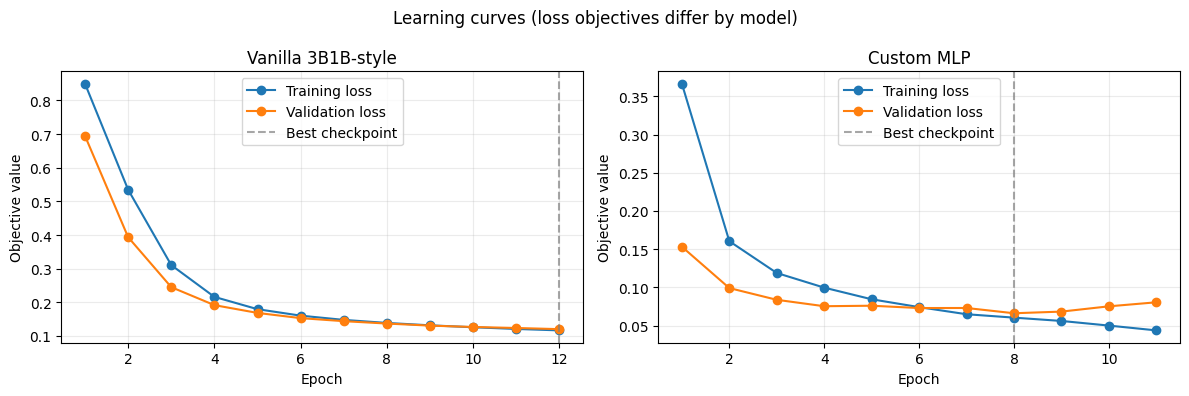

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, model_name in zip(axes, MODEL_CONFIGS):
    history = histories[model_name]
    epochs = [row["epoch"] for row in history]
    ax.plot(epochs, [row["train_loss"] for row in history], marker="o", label="Training loss")
    ax.plot(epochs, [row["validation_loss"] for row in history], marker="o", label="Validation loss")
    ax.axvline(best_epochs[model_name], color="gray", linestyle="--", alpha=0.7, label="Best checkpoint")
    ax.set_title(model_name)
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Objective value")
    ax.grid(alpha=0.25)
    ax.legend()
fig.suptitle("Learning curves (loss objectives differ by model)")
plt.tight_layout()
plt.show()

### - Confusion matrices


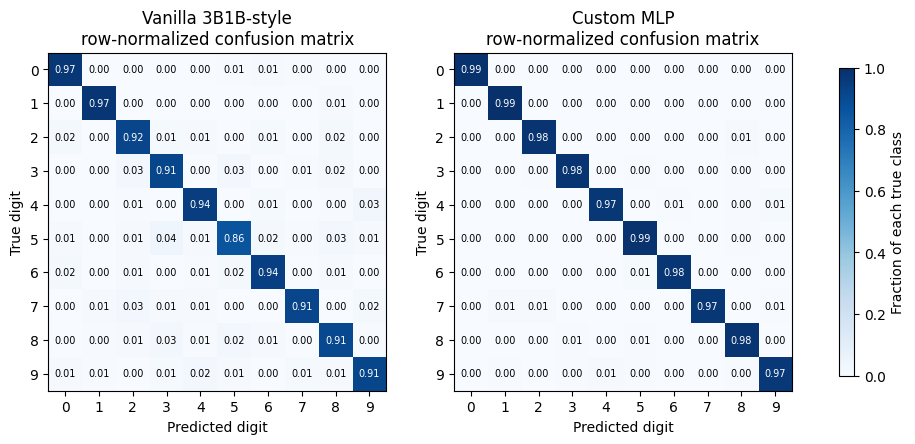

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, (model_name, confusion) in zip(axes, confusion_matrices.items()):
    row_totals = confusion.sum(dim=1, keepdim=True).clamp_min(1)
    row_normalized = (confusion.to(torch.float32) / row_totals).numpy()
    image = ax.imshow(row_normalized, cmap="Blues", vmin=0, vmax=1)
    ax.set_title(f"{model_name}\nrow-normalized confusion matrix")
    ax.set_xlabel("Predicted digit")
    ax.set_ylabel("True digit")
    ax.set_xticks(range(NUM_CLASSES))
    ax.set_yticks(range(NUM_CLASSES))
    for row in range(NUM_CLASSES):
        for column in range(NUM_CLASSES):
            value = row_normalized[row, column]
            ax.text(column, row, f"{value:.2f}", ha="center", va="center",
                    color="white" if value > 0.55 else "black", fontsize=7)
fig.colorbar(image, ax=axes.ravel().tolist(), shrink=0.8, label="Fraction of each true class")
plt.show()

## 9 - GPU use
Device checks show whether models and batches use CUDA. Timing synchronizes GPU work before and after measurement. CUDA placement does not establish full utilization: data loading and these small networks may limit efficiency.


In [21]:
print("Notebook training device:", DEVICE)
for model_name, result in final_results.items():
    memory_text = (
        f"{result['peak_memory_mb']:.1f} MiB peak allocated"
        if result["peak_memory_mb"] is not None else "not applicable on CPU"
    )
    print(
        f"{model_name}: train-loop time {result['training_seconds']:.2f}s; "
        f"{result['parameters']:,} parameters; {memory_text}"
    )
if DEVICE.type == "cuda":
    print("CUDA device used by vanilla model:", next(vanilla_model.parameters()).device)
    print("CUDA device used by custom model:", next(custom_model.parameters()).device)
else:
    print("This run did not use GPU acceleration because CUDA was unavailable in the selected kernel.")

Notebook training device: cpu
Vanilla 3B1B-style: train-loop time 85.63s; 13,002 parameters; not applicable on CPU
Custom MLP: train-loop time 100.65s; 235,146 parameters; not applicable on CPU
This run did not use GPU acceleration because CUDA was unavailable in the selected kernel.


## 10 - conclusion


In [22]:
if not cv_results:
    raise RuntimeError("Run the Section 5 cross-validation timing cell before this discussion cell.")

vanilla_name = "Vanilla 3B1B-style"
custom_name = "Custom MLP"
vanilla_result = final_results[vanilla_name]
custom_result = final_results[custom_name]
accuracy_change_pp = 100 * (custom_result["test"]["accuracy"] - vanilla_result["test"]["accuracy"])
parameter_ratio = custom_result["parameters"] / vanilla_result["parameters"]
time_ratio = custom_result["training_seconds"] / max(vanilla_result["training_seconds"], 1e-12)
vanilla_gap = 100 * (vanilla_result["train"]["accuracy"] - vanilla_result["validation"]["accuracy"])
custom_gap = 100 * (custom_result["train"]["accuracy"] - custom_result["validation"]["accuracy"])

if accuracy_change_pp > 0:
    outcome = f"The custom model improved test accuracy by {accuracy_change_pp:.2f} percentage points."
elif accuracy_change_pp < 0:
    outcome = f"The vanilla model had {abs(accuracy_change_pp):.2f} percentage points higher test accuracy."
else:
    outcome = "The models had the same test accuracy."

discussion = [
    f"The vanilla model achieved **{vanilla_result['test']['accuracy']:.2%}** test accuracy and "
    f"{vanilla_result['test']['macro_f1']:.3f} macro F1. The custom model achieved "
    f"**{custom_result['test']['accuracy']:.2%}** and {custom_result['test']['macro_f1']:.3f}. {outcome}",
    f"The custom model has {parameter_ratio:.1f} times as many parameters. Its training loop took "
    f"{custom_result['training_seconds']:.1f} seconds, compared with "
    f"{vanilla_result['training_seconds']:.1f} seconds for vanilla ({time_ratio:.2f} times the duration). "
    "A larger model needs more computation per batch, but measured time also depends on batch size, "
    "optimizer overhead and the number of epochs completed.",

]
display(Markdown("\n\n".join(discussion)))


The vanilla model achieved **92.62%** test accuracy and 0.925 macro F1. The custom model achieved **97.92%** and 0.979. The custom model improved test accuracy by 5.30 percentage points.

The custom model has 18.1 times as many parameters. Its training loop took 100.7 seconds, compared with 85.6 seconds for vanilla (1.18 times the duration). A larger model needs more computation per batch, but measured time also depends on batch size, optimizer overhead and the number of epochs completed.